# การจัดกลุ่มหลักสูตรปริญญาตรีตามระดับการเปิดรับ AI (AI Exposure Clustering)

**วัตถุประสงค์:** จัดกลุ่มหลักสูตรระดับปริญญาตรีของสหรัฐฯ ตามการเปิดรับ AI ของอาชีพที่เกี่ยวข้อง ด้วย K-Means แล้วเปรียบเทียบว่าแต่ละกลุ่มมี **รายได้ หนี้ และการมีงานทำ** ต่างกันหรือไม่

## 1. ภาพรวมขั้นตอนการทำงาน

| ขั้นตอน | สิ่งที่ทำ | ผลลัพธ์หลัก |
|---|---|---|
| 0. ติดตั้งไลบรารี | `pip install` ไลบรารีที่ใช้ | พร้อมรัน |
| 1. นำเข้าข้อมูล | อ่านไฟล์ CSV ด้วย pandas ตรวจขนาด ชนิดข้อมูล และสัดส่วน NaN | 227,980 แถว × 72 คอลัมน์ |
| 2. เตรียมข้อมูล | เลือกเฉพาะปริญญาตรี (`credential_level == 3`) และตัดแถวที่ไม่มีค่าตัวแปรหลัก | 71,664 → 68,385 หลักสูตร |
| 3. สำรวจข้อมูล (EDA) | ดูการกระจายของตัวแปร AI | เบ้ขวามาก, 61.8% มีค่าเป็น 0 |
| 4. เลือกตัวแปรและจำนวนกลุ่ม | ปรับสเกล (StandardScaler) แล้วทดลอง K-Means ที่ k = 2–8 ดู Elbow และ Silhouette | ตารางเทียบ k |
| 5. สร้างโมเดลสุดท้าย | K-Means ที่ k = 4 | 4 กลุ่ม |
| 6. ทดสอบความต่างระหว่างกลุ่ม | สรุปค่ามัธยฐาน, Kruskal–Wallis, ขนาดผล (ε²), ดัชนีคุณภาพการจัดกลุ่ม | ดูหัวข้อ "สรุปผล" ท้าย notebook |
| 7–8. แสดงผลเป็นภาพ | Scatter, Centroid, Elbow/Silhouette, Boxplot, สาขาที่พบมากในแต่ละกลุ่ม (ฉบับอังกฤษและไทย) | ไฟล์ PNG |

## 2. แหล่งข้อมูล

- **ไฟล์ที่ใช้:** `college_majors_2026.csv` — 1 แถว = 1 หลักสูตร (`program_id`) ของ 1 สถาบัน, 227,980 แถว × 72 คอลัมน์
- **คอลัมน์ที่ใช้วิเคราะห์:**
  - `credential_level` (กรองเอา 3 = ปริญญาตรี) และ `cip_family_title` (กลุ่มสาขาวิชา)
  - ตัวแปรจัดกลุ่ม: `ai_software_occupation_share` (**ความกว้าง**: สัดส่วนอาชีพที่ใช้ซอฟต์แวร์ AI, ช่วง 0–1) และ `ai_tools_max_per_occupation` (**ความเข้มข้น**: จำนวนเครื่องมือ AI สูงสุดต่ออาชีพ, ช่วง 0–10)
  - ตัวแปรผลลัพธ์: `median_earnings_4yr_usd`, `median_debt_usd`, `pct_working_5yr`
- **ที่มา:** ⚠️ **TODO — ใส่ชื่อ/ลิงก์ชุดข้อมูลที่ดาวน์โหลดมา** (notebook นี้ไม่ได้ระบุไว้ และโหลดจากไฟล์ในเครื่อง)
  - หมายเหตุ: โครงสร้างคอลัมน์ (`unitid`, `opeid6`, รหัส CIP, `credential_level`, รายได้/หนี้รายหลักสูตร) สอดคล้องกับข้อมูล *Field of Study* ของ U.S. Department of Education College Scorecard ([เอกสารประกอบ](https://collegescorecard.ed.gov/files/FieldOfStudyDataDocumentation.pdf)) ส่วนคอลัมน์ `ai_*` ไม่ใช่คอลัมน์มาตรฐานของ Scorecard จึงควรตรวจสอบนิยามจากหน้าเอกสารของชุดข้อมูลที่ใช้จริง

## 3. ไลบรารีที่จำเป็น

| ไลบรารี | ใช้ทำอะไร | เวอร์ชันที่ใช้รันจริง |
|---|---|---|
| pandas | อ่าน/จัดการข้อมูล | 3.0.6 |
| numpy | คำนวณเชิงตัวเลข | 2.5.3 |
| scikit-learn | `StandardScaler`, `KMeans`, `silhouette_score`, `calinski_harabasz_score`, `davies_bouldin_score` | 1.9.1 |
| scipy | `kruskal` (Kruskal–Wallis) | 1.18.1 |
| matplotlib | กราฟทั้งหมด | 3.11.2 |
| seaborn | `boxplot` | (ไม่ปรากฏเวอร์ชันในผลลัพธ์) |
| jupyter / ipykernel | รัน notebook | — |
| kaggle, kagglehub *(ไม่บังคับ)* | ใช้เมื่อดาวน์โหลดข้อมูลจาก Kaggle ด้วยตนเอง — ติดตั้งไว้แต่ notebook นี้ไม่ได้เรียกใช้ | 2.2.4 / 1.0.2 |

เวอร์ชันข้างต้นอ่านจากผลลัพธ์การติดตั้งใน notebook (Python 3.13 บน Windows)

```bash
pip install pandas numpy scipy scikit-learn matplotlib seaborn jupyter
```

## 4. วิธีรัน

1. ติดตั้ง Python และไลบรารีตามหัวข้อ 3
2. วางไฟล์ `college_majors_2026.csv` ไว้ในเครื่อง แล้ว **แก้พาธ** ในโค้ดให้ตรงกับเครื่องของคุณ (เดิมคือ `E:/Code/data sci/data/college_majors_2026.csv` ปรากฏ 3 จุด: ขั้นตอนนำเข้าข้อมูล, รอบจัดกลุ่มรอบแรก และตอนโหลดซ้ำเพื่อตรวจ NaN)
3. เปิด notebook ด้วย `jupyter notebook main.ipynb` (หรือเปิดใน VS Code) เลือก kernel Python 3
4. รันเซลล์ **เรียงจากบนลงล่าง** (Run All) — บางเซลล์ใช้ตัวแปรจากเซลล์ก่อนหน้า เช่น `d`, `X`, `Xs`, `scaler`, `kmeans_final`
5. ไฟล์ภาพจะถูกบันทึกในโฟลเดอร์ทำงานปัจจุบัน: `cluster_comparison.png`, `cluster_scatter.png`, `cluster_centroids.png`, `elbow_silhouette.png`, `cluster_boxplots.png`, `cluster_top_fields.png`, `silhouette_bar.png` และฉบับภาษาไทย `*_th.png` (`cluster_scatter_th`, `cluster_centroids_th`, `elbow_silhouette_th`, `cluster_boxplots_th`, `cluster_top_fields_th`)

**ข้อควรระวังในการรัน**

- บรรทัด `!pip install StandardScaler` ในเซลล์ติดตั้ง **ไม่จำเป็น** และเป็นคนละแพ็กเกจกับคลาส `StandardScaler` ของ scikit-learn (ตัวจริงมากับ `scikit-learn` อยู่แล้ว)
- ฟอนต์ไทยที่ตั้งไว้ (`Leelawadee UI`, `Tahoma`) เป็นฟอนต์ของ Windows; บน macOS/Linux ให้เปลี่ยนเป็นฟอนต์ไทยที่มีในเครื่อง ไม่เช่นนั้นกราฟฉบับไทยจะแสดงตัวอักษรเป็นกล่อง
- ชื่อกลุ่ม (`labels_name`, `names_th`) และสีถูกผูกกับ **หมายเลขกลุ่มของการรันครั้งนี้** (0–3) ถ้าเปลี่ยนข้อมูลหรือเวอร์ชันไลบรารี หมายเลขกลุ่มอาจสลับกัน ให้ตรวจ Centroid ก่อนใช้ชื่อเดิม
- การคำนวณ ε² (Epsilon-squared) ในส่วนทดสอบ พิมพ์ค่า H และ n จากผล Kruskal–Wallis ลงในโค้ดโดยตรง หากข้อมูลเปลี่ยนต้องอัปเดตค่าเหล่านี้ด้วย

---
## ขั้นตอนที่ 0 — ติดตั้งไลบรารี
รันครั้งเดียวต่อเครื่อง ข้ามได้หากติดตั้งแล้ว (ดูรายการที่จำเป็นและข้อสังเกตเรื่อง `StandardScaler` ที่ส่วนบนสุด)

In [ ]:
!pip install kaggle
!pip install kagglehub
!pip install pandas
!pip install numpy
!pip install StandardScaler
!pip install scikit-learn
!pip install matplotlib
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable


...


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


---
## ขั้นตอนที่ 1 — นำเข้าข้อมูล
อ่านไฟล์ CSV ด้วย `pd.read_csv` แล้วตรวจขนาด (227,980 แถว × 72 คอลัมน์) ชนิดข้อมูล ตัวอย่าง 10 แถว และสัดส่วน NaN ของแต่ละคอลัมน์

⚠️ พาธไฟล์เป็นพาธตายตัวของเครื่องเดิม ต้องแก้ก่อนรัน

In [2]:
import pandas as pd
df = pd.read_csv("E:/Code/data sci/data/college_majors_2026.csv")

print(df.shape)
print(df.dtypes)
print(df[["credential_level", "cip_family_title",
          "ai_software_occupation_share",
          "median_earnings_4yr_usd", "median_debt_usd", "pct_working_5yr"]].head(10))
print(df.isna().mean().sort_values(ascending=False).head(15))

(227980, 72)
program_id                 str
unitid                 float64
opeid6                   int64
institution_name           str
institution_control        str
                        ...   
ai_tool_examples           str
earnings_4yr_status        str
earnings_1yr_status        str
earnings_5yr_status        str
debt_status                str
Length: 72, dtype: object
   credential_level                                   cip_family_title  \
0                 1            Health Professions and Related Programs   
1                 1            Health Professions and Related Programs   
2                 1  Business, Management, Marketing, and Related S...   
3                 1     Culinary, Entertainment, and Personal Services   
4                 5                                          Education   
5                 6                                          Education   
6                 8                                          Education   
7                 5         

---
## ขั้นตอนที่ 2 — เตรียมข้อมูล
1. ยืนยันความหมายของ `credential_level` ด้วยคอลัมน์ชื่อระดับและสาขาที่พบ แล้วเลือกเฉพาะ **`credential_level == 3` (ปริญญาตรี)** → **71,664** หลักสูตร
2. ตัดแถวที่ไม่มีค่าตัวแปรหลักด้วย `dropna` → **68,385** หลักสูตร (ตัดออก 3,279 แถว)
3. ตรวจค่าติดลบและแถวซ้ำ — ไม่พบทั้งสองอย่าง (0 และ 0)

In [3]:
# เช็กว่ามี column อื่นที่ช่วยยืนยันไหม เช่น ชื่อเต็มของ credential
print(df.filter(regex="credential|level_name|degree_name", axis=1).columns.tolist())

# เทียบ cross-check: สาขาที่ระดับ 3 ควรมีทั้ง Business, Engineering, Health ฯลฯ (สาขาปริญญาตรีทั่วไป)
print(df[df["credential_level"] == 3]["cip_family_title"].value_counts().head(10))

['credential_level', 'credential_name']
cip_family_title
Business, Management, Marketing, and Related Support Services    8625
Health Professions and Related Programs                          5634
Visual and Performing Arts                                       5441
Social Sciences                                                  5218
Education                                                        3764
Biological and Biomedical Sciences                               3680
Engineering                                                      3365
Multi/Interdisciplinary Studies                                  3161
Computer and Information Sciences and Support Services           3119
Physical Sciences                                                2827
Name: count, dtype: int64


In [4]:
d = df[df["credential_level"] == 3].copy()   # ใช้ตัวเลข ไม่ใช่ string  
print(len(d))   # ควรได้ 71664

driver = "ai_software_occupation_share"
n_before = len(d)
d = d.dropna(subset=[driver])
print(n_before, "->", len(d))

print(d[driver].describe())
print((d[driver] < 0).sum())
print(d.duplicated().sum())

71664
71664 -> 68385
count    68385.000000
mean         0.094086
std          0.168801
min          0.000000
25%          0.000000
50%          0.000000
75%          0.111000
max          1.000000
Name: ai_software_occupation_share, dtype: float64
0
0


---
## ขั้นตอนที่ 3 — สำรวจข้อมูล (EDA)
ดูการกระจายของ `ai_software_occupation_share`: ค่ามัธยฐานและ Q1 เป็น 0 และมี **42,281 จาก 68,385 หลักสูตร (61.8%)** ที่มีค่า 0 พอดี จึงวาดฮิสโทแกรม 2 แผง (ค่าทั้งหมด / เฉพาะค่าที่ > 0) เพื่อดูส่วนที่เหลือ

ข้อมูลนี้เบ้ขวาอย่างรุนแรง (heavily right-skewed): median และ Q1 เป็น 0 ทั้งคู่ หมายความว่ามากกว่าครึ่งของสาขาวิชามี AI Exposure = 0 พอดี ไม่ใช่แค่น้อย แต่เป็นศูนย์เป๊ะ ส่วนที่เหลือกระจายไปจนถึง 1.0

42281 จาก 68385 = 0.618278862323609


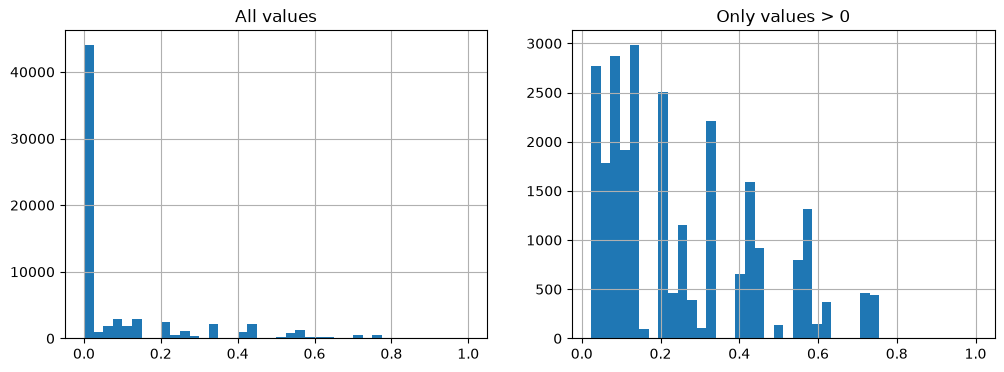

In [5]:
import matplotlib.pyplot as plt

print((d[driver] == 0).sum(), "จาก", len(d), "=", (d[driver] == 0).mean())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d[driver].hist(bins=40, ax=axes[0])
axes[0].set_title("All values")
d[d[driver] > 0][driver].hist(bins=40, ax=axes[1])
axes[1].set_title("Only values > 0")
plt.show()

---
## ขั้นตอนที่ 4 — เลือกตัวแปรจัดกลุ่มและจำนวนกลุ่ม (k)
ใช้ 2 ตัวแปร ได้แก่ **ความกว้าง** (`ai_software_occupation_share`) และ **ความเข้มข้น** (`ai_tools_max_per_occupation`)

- สหสัมพันธ์ระหว่างสองตัวแปร r = 0.787 และค่า NaN ของทั้งคู่อยู่ในแถวเดียวกัน (3,279 แถว) จึงเหลือ 68,385 แถวเท่าเดิม
- ปรับสเกลด้วย `StandardScaler` แล้วรัน `KMeans(n_init=10, random_state=42)` ที่ k = 2–8 เทียบ Inertia (Elbow) และ Silhouette
- จากนั้นเทียบโปรไฟล์ของกลุ่มที่ k = 4, 5, 6
- เซลล์ในส่วนนี้ทำงานทับซ้อนกันบางส่วน (รอบแรก → ตรวจ NaN/สหสัมพันธ์ → รันซ้ำฉบับที่ใช้จริง) รันเรียงตามลำดับได้เลย

| k | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|
| Inertia | 37,308 | 21,132 | 14,918 | 10,175 | 7,092 | 5,070 | 3,487 |
| Silhouette | 0.806 | 0.753 | 0.762 | 0.768 | 0.790 | 0.820 | 0.829 |

> **หมายเหตุ:** Silhouette ไม่ได้สูงสุดที่ k = 4 (สูงสุดที่ k = 8 = 0.829) แต่ผู้วิเคราะห์เลือก k = 4 เป็นโมเดลสุดท้าย ⚠️ **TODO — เติมเหตุผลที่เลือก k = 4 ตรงนี้** (notebook ไม่ได้บันทึกไว้)

In [6]:
import pandas as pd
import numpy as np

# 1. โหลดข้อมูล
df = pd.read_csv("E:/Code/data sci/data/college_majors_2026.csv")

# 2. กรองประชากร
d = df[df["credential_level"] == 3].copy()

# 3. กำหนด driver และคัดแถวที่ไม่มี NaN
drivers = ["ai_software_occupation_share", "ai_tools_max_per_occupation"]

print("NaN ก่อนกรอง:\n", d[drivers].isna().sum())   # เช็กก่อน

X = d[drivers].dropna().copy()   # ต้องมี .dropna() ตรงนี้แน่ ๆ

print("NaN หลังกรอง:\n", X.isna().sum())            # ต้องเป็น 0 ทั้งคู่
print("จำนวนแถว X:", len(X))

# 4. ยืนยันว่า X สะอาดจริงก่อนเข้า StandardScaler
assert X.isna().sum().sum() == 0, "ยังมี NaN หลุดอยู่!"

# 5. Standardize
from sklearn.preprocessing import StandardScaler
Xs = StandardScaler().fit_transform(X)

# 6. Elbow + Silhouette
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    sil = silhouette_score(Xs, km.labels_)
    results.append((k, km.inertia_, sil))

result_df = pd.DataFrame(results, columns=["k", "inertia", "silhouette"])
print(result_df)

NaN ก่อนกรอง:
 ai_software_occupation_share    3279
ai_tools_max_per_occupation     3279
dtype: int64
NaN หลังกรอง:
 ai_software_occupation_share    0
ai_tools_max_per_occupation     0
dtype: int64
จำนวนแถว X: 68385
   k       inertia  silhouette
0  2  37308.323505    0.806404
1  3  21131.833955    0.753224
2  4  14917.970783    0.761659
3  5  10174.824380    0.767691
4  6   7092.025608    0.790380
5  7   5069.967899    0.819856
6  8   3487.328737    0.829319


In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv("E:/Code/data sci/data/college_majors_2026.csv")
df.head()
print("\nCount of NaN in each column:\n", df.isnull().sum())


Count of NaN in each column:
 program_id                  0
unitid                   7020
opeid6                      0
institution_name            0
institution_control         0
                        ...  
ai_tool_examples       153550
earnings_4yr_status         0
earnings_1yr_status         0
earnings_5yr_status         0
debt_status                 0
Length: 72, dtype: int64


In [8]:
print(df.filter(regex="ai_", axis=1).columns.tolist())

['occupations_using_ai_software', 'ai_software_occupation_share', 'ai_tools_max_per_occupation', 'ai_tool_examples']


In [9]:
print(d["ai_tools_max_per_occupation"].describe())
print(d["ai_tools_max_per_occupation"].isna().mean())
print(d[["ai_software_occupation_share", "ai_tools_max_per_occupation"]].corr())

count    68385.000000
mean         1.552928
std          2.953609
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max         10.000000
Name: ai_tools_max_per_occupation, dtype: float64
0.045755190890823846
                              ai_software_occupation_share  \
ai_software_occupation_share                      1.000000   
ai_tools_max_per_occupation                       0.787237   

                              ai_tools_max_per_occupation  
ai_software_occupation_share                     0.787237  
ai_tools_max_per_occupation                      1.000000  


In [10]:
drivers = ["ai_software_occupation_share", "ai_tools_max_per_occupation"]
X = d[drivers].dropna()
n_before = len(d)
print(n_before, "->", len(X))

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Xs = StandardScaler().fit_transform(X)

results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    sil = silhouette_score(Xs, km.labels_)
    results.append((k, km.inertia_, sil))

result_df = pd.DataFrame(results, columns=["k", "inertia", "silhouette"])
print(result_df)

71664 -> 68385
   k       inertia  silhouette
0  2  37308.323505    0.806404
1  3  21131.833955    0.753224
2  4  14917.970783    0.761659
3  5  10174.824380    0.767691
4  6   7092.025608    0.790380
5  7   5069.967899    0.819856
6  8   3487.328737    0.829319


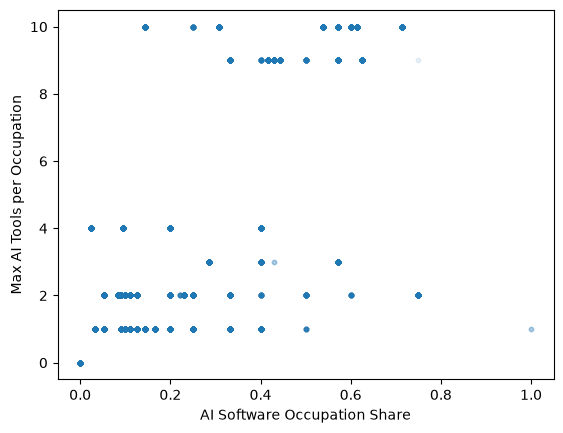

In [11]:
import matplotlib.pyplot as plt
plt.scatter(X["ai_software_occupation_share"], X["ai_tools_max_per_occupation"], alpha=0.1, s=10)
plt.xlabel("AI Software Occupation Share")
plt.ylabel("Max AI Tools per Occupation")
plt.show()

In [12]:
for k in [4, 5, 6]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    d.loc[X.index, f"cluster_k{k}"] = km.labels_
    print(f"--- k={k} ---")
    print(d.groupby(f"cluster_k{k}")[drivers].agg(["count", "mean", "min", "max"]).round(3))
    print()

--- k=4 ---
           ai_software_occupation_share                       \
                                  count   mean    min    max   
cluster_k4                                                     
0.0                               43955  0.002  0.000  0.053   
1.0                                7260  0.442  0.143  0.750   
2.0                                3538  0.407  0.286  1.000   
3.0                               13632  0.126  0.024  0.250   

           ai_tools_max_per_occupation                    
                                 count   mean  min   max  
cluster_k4                                                
0.0                              43955  0.038  0.0   1.0  
1.0                               7260  9.542  9.0  10.0  
2.0                               3538  2.031  1.0   4.0  
3.0                              13632  2.059  1.0   4.0  

--- k=5 ---
           ai_software_occupation_share                       \
                                  count   mean   

---
## ขั้นตอนที่ 5 — สร้างโมเดลสุดท้าย (K-Means, k = 4)
ฟิตโมเดลที่ k = 4 บนข้อมูลที่ปรับสเกลแล้ว ได้ 68,385 หลักสูตรแบ่งเป็น 4 กลุ่ม

| กลุ่ม | ชื่อที่ตั้งไว้ | จำนวนหลักสูตร | ความกว้างเฉลี่ย | ความเข้มข้นเฉลี่ย (จำนวนเครื่องมือ) |
|---|---|---|---|---|
| 0 | ไม่มีการเปิดรับ AI | 43,955 | 0.002 | 0.04 |
| 1 | เข้มข้นสูง (กว้างปานกลาง) | 7,260 | 0.442 | 9.54 |
| 2 | กว้างสูง เข้มข้นต่ำ | 3,538 | 0.407 | 2.03 |
| 3 | กว้างต่ำ เข้มข้นต่ำ | 13,632 | 0.126 | 2.06 |

> **ข้อสังเกต:** ความกว้างเฉลี่ยของกลุ่ม 1 (0.442) สูงกว่ากลุ่ม 2 (0.407) ขณะที่ชื่อกลุ่มเรียกกลุ่ม 2 ว่า "กว้างสูง" และกลุ่ม 1 ว่า "กว้างปานกลาง" (กลุ่ม 2 มีช่วงค่าตั้งแต่ 0.286 ถึง 1.0 ส่วนกลุ่ม 1 อยู่ที่ 0.143–0.75) ควรทบทวนว่าชื่อกลุ่มสื่อความหมายตรงกับที่ต้องการหรือไม่

In [13]:
K = 4
kmeans_final = KMeans(n_clusters=K, n_init=10, random_state=42)
kmeans_final.fit(Xs)

d = d.loc[X.index].copy()          # ตัดแถวที่ไม่มี driver ออก
d["cluster"] = kmeans_final.labels_
d["cluster"] = d["cluster"].astype(int)

print(len(d))                       # ควรได้ 68385
print(d["cluster"].value_counts())  # ควรตรงกับ 43955, 7260, 3538, 13632

68385
cluster
0    43955
3    13632
1     7260
2     3538
Name: count, dtype: int64


---
## ขั้นตอนที่ 6 — ทดสอบความต่างของผลลัพธ์ระหว่างกลุ่ม
เปรียบเทียบ 3 ตัวแปรผลลัพธ์ (รายได้มัธยฐาน 4 ปีหลังจบ, หนี้มัธยฐาน, % มีงานทำ 5 ปีหลังจบ) ระหว่าง 4 กลุ่ม

1. **ตารางสรุป** ค่ามัธยฐานของแต่ละกลุ่ม
2. **Kruskal–Wallis** ทดสอบแบบไม่อิงพารามิเตอร์ (ไม่ต้องสมมติว่าข้อมูลเป็นปกติ) ใช้เฉพาะแถวที่มีค่าของตัวแปรนั้น
3. **Boxplot** เทียบการกระจายของแต่ละกลุ่ม
4. **ดัชนีคุณภาพการจัดกลุ่ม** Silhouette 0.762, Calinski–Harabasz 186,181.8, Davies–Bouldin 0.681
5. **ขนาดผล ε² = H / (n − 1)** เพราะ p-value ของข้อมูลขนาดใหญ่เล็กมากเสมอ จึงต้องดูขนาดผลควบคู่

In [14]:
compare_vars = ["median_earnings_4yr_usd", "median_debt_usd", "pct_working_5yr"]

summary = d.groupby("cluster").agg(
    n_programs=("ai_software_occupation_share", "size"),
    software_share_mean=("ai_software_occupation_share", "mean"),
    tools_mean=("ai_tools_max_per_occupation", "mean"),
    earnings_median=("median_earnings_4yr_usd", "median"),
    debt_median=("median_debt_usd", "median"),
    pct_working_median=("pct_working_5yr", "median"),
)
print(summary.round(3))

         n_programs  software_share_mean  tools_mean  earnings_median  \
cluster                                                                 
0             43955                0.002       0.038          55532.0   
1              7260                0.442       9.542          80623.0   
2              3538                0.407       2.031          82632.0   
3             13632                0.126       2.059          61884.0   

         debt_median  pct_working_median  
cluster                                   
0            23000.0               94.60  
1            22125.0               95.10  
2            23000.0               95.75  
3            23250.0               95.00  


In [15]:
from scipy.stats import kruskal

results = []
for var in compare_vars:
    sub = d.dropna(subset=[var, "cluster"])
    groups = [g[var].values for _, g in sub.groupby("cluster")]
    stat, p = kruskal(*groups)
    results.append({"variable": var, "H": round(stat, 2), "p_value": p, "n": len(sub)})

print(pd.DataFrame(results))

                  variable        H       p_value      n
0  median_earnings_4yr_usd  4032.12  0.000000e+00  26605
1          median_debt_usd    76.04  2.170203e-16  25070
2          pct_working_5yr   166.81  6.223762e-36  23891


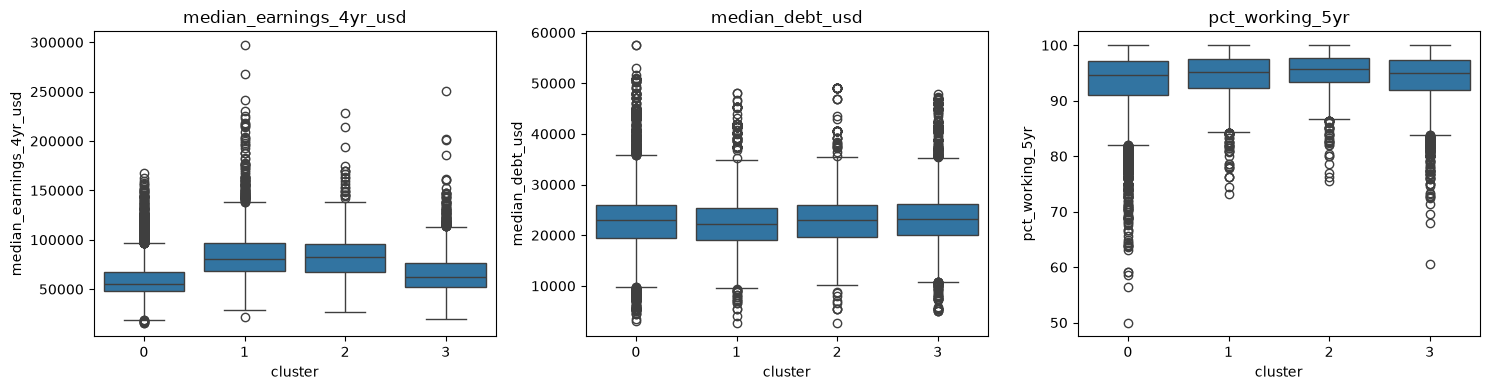

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, compare_vars):
    sns.boxplot(data=d, x="cluster", y=var, ax=ax)
    ax.set_title(var)
plt.tight_layout()
plt.savefig("cluster_comparison.png", dpi=150)
plt.show()

In [17]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

print("Silhouette:", silhouette_score(Xs, d["cluster"]))
print("Calinski-Harabasz:", calinski_harabasz_score(Xs, d["cluster"]))
print("Davies-Bouldin:", davies_bouldin_score(Xs, d["cluster"]))

Silhouette: 0.7616586677806629
Calinski-Harabasz: 186181.7922128515
Davies-Bouldin: 0.6814887005144165


In [18]:
def epsilon_squared(H, n):
    return H / (n - 1)

for var, H, n in [("earnings", 4032.12, 26605), ("debt", 76.04, 25070), ("pct_working", 166.81, 23891)]:
    eps2 = epsilon_squared(H, n)
    print(f"{var}: epsilon² = {eps2:.4f}")

earnings: epsilon² = 0.1516
debt: epsilon² = 0.0030
pct_working: epsilon² = 0.0070


---
## ขั้นตอนที่ 7 — ภาพประกอบผล (ฉบับภาษาอังกฤษ)
Scatter แยกตามกลุ่ม, ตำแหน่ง Centroid (แปลงกลับเป็นสเกลเดิมด้วย `scaler.inverse_transform` ซึ่งต้องรันเซลล์ที่สร้าง `scaler` ก่อน), กราฟ Elbow/Silhouette, Boxplot ของผลลัพธ์ทั้งสาม, สาขาวิชาที่พบมากสุด 5 อันดับของแต่ละกลุ่ม และแท่ง Silhouette ต่อ k

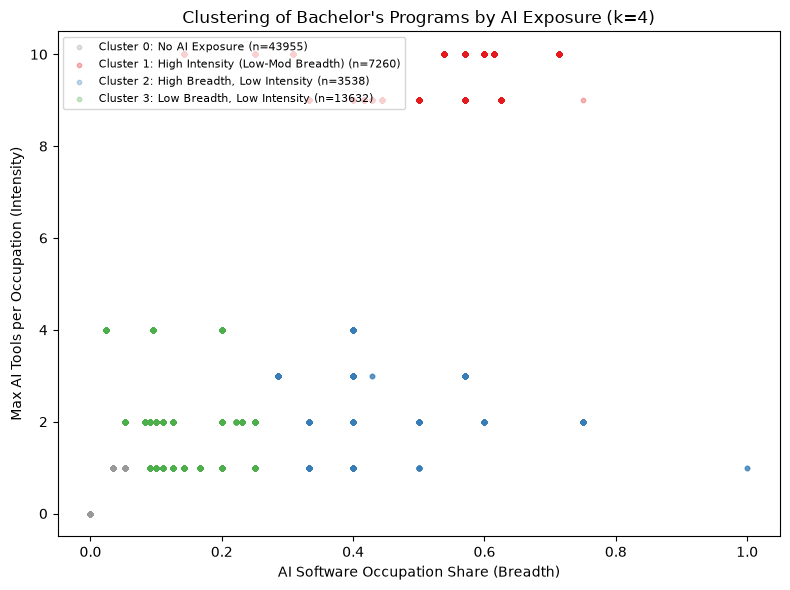

In [19]:
import matplotlib.pyplot as plt

colors = {0: "#999999", 1: "#e41a1c", 2: "#377eb8", 3: "#4daf4a"}
labels_name = {
    0: "No AI Exposure",
    1: "High Intensity (Low-Mod Breadth)",
    2: "High Breadth, Low Intensity",
    3: "Low Breadth, Low Intensity"
}

fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(d["cluster"].unique()):
    sub = d[d["cluster"] == c]
    ax.scatter(sub["ai_software_occupation_share"], sub["ai_tools_max_per_occupation"],
               s=10, alpha=0.3, color=colors[c], label=f"Cluster {c}: {labels_name[c]} (n={len(sub)})")

ax.set_xlabel("AI Software Occupation Share (Breadth)")
ax.set_ylabel("Max AI Tools per Occupation (Intensity)")
ax.set_title("Clustering of Bachelor's Programs by AI Exposure (k=4)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("cluster_scatter.png", dpi=150)
plt.show()

In [20]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

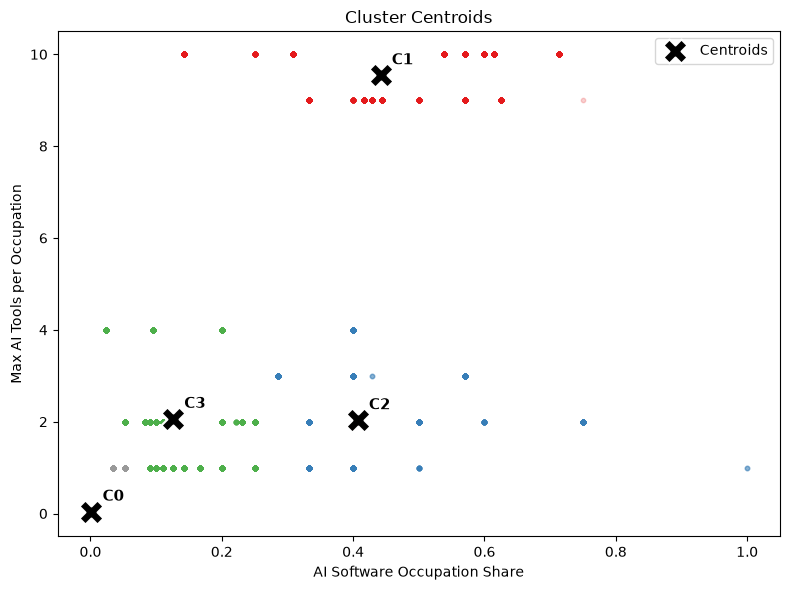

In [21]:
centroids_original = scaler.inverse_transform(kmeans_final.cluster_centers_)  # ต้องมี scaler ตัวแปรเดิมที่ fit ไว้

fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(d["cluster"].unique()):
    sub = d[d["cluster"] == c]
    ax.scatter(sub["ai_software_occupation_share"], sub["ai_tools_max_per_occupation"],
               s=10, alpha=0.2, color=colors[c])

ax.scatter(centroids_original[:, 0], centroids_original[:, 1],
           c="black", marker="X", s=300, edgecolor="white", linewidth=1.5, label="Centroids", zorder=5)
for i, (x, y) in enumerate(centroids_original):
    ax.annotate(f"C{i}", (x, y), fontsize=11, fontweight="bold",
                xytext=(8, 8), textcoords="offset points")

ax.set_xlabel("AI Software Occupation Share")
ax.set_ylabel("Max AI Tools per Occupation")
ax.set_title("Cluster Centroids")
ax.legend()
plt.tight_layout()
plt.savefig("cluster_centroids.png", dpi=150)
plt.show()

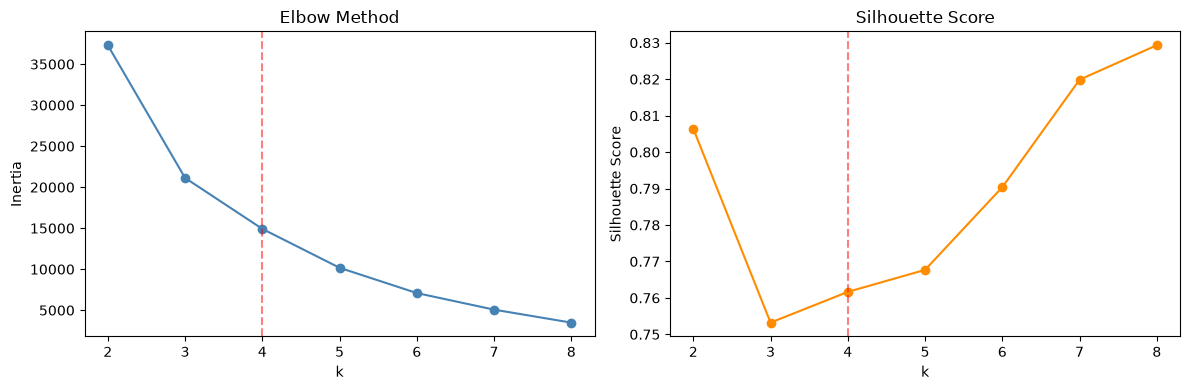

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(result_df["k"], result_df["inertia"], marker="o", color="steelblue")
axes[0].axvline(x=4, color="red", linestyle="--", alpha=0.5)
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")

axes[1].plot(result_df["k"], result_df["silhouette"], marker="o", color="darkorange")
axes[1].axvline(x=4, color="red", linestyle="--", alpha=0.5)
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score")
plt.tight_layout()
plt.savefig("elbow_silhouette.png", dpi=150)
plt.show()

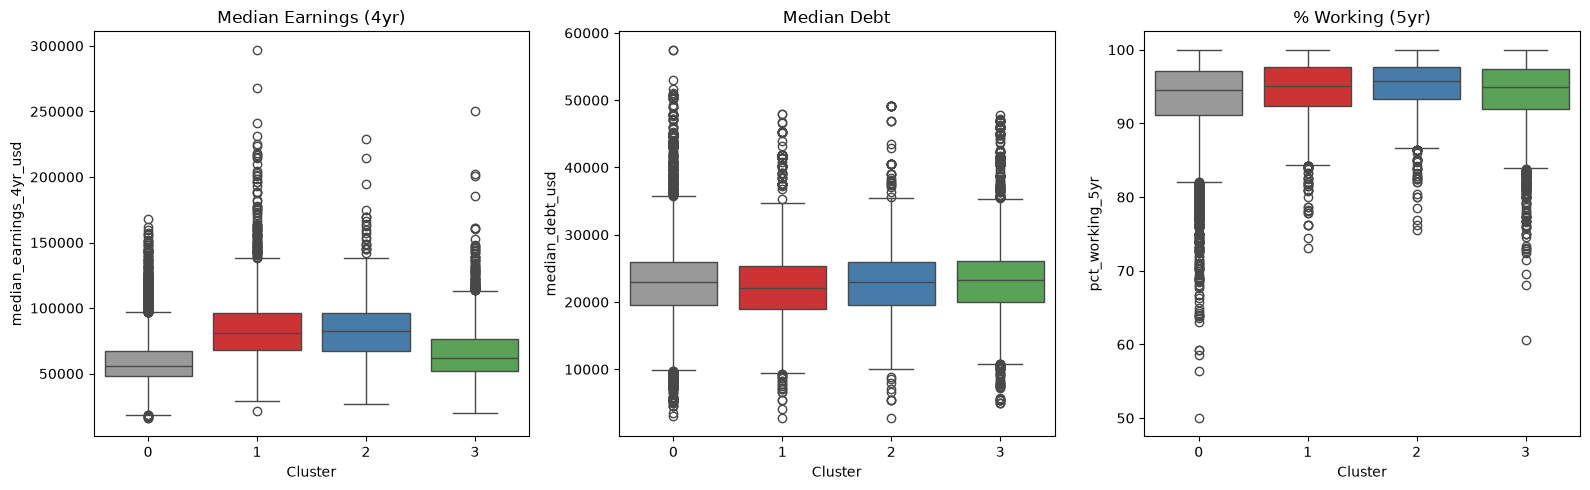

In [23]:
import seaborn as sns

compare_vars = ["median_earnings_4yr_usd", "median_debt_usd", "pct_working_5yr"]
titles = ["Median Earnings (4yr)", "Median Debt", "% Working (5yr)"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, var, title in zip(axes, compare_vars, titles):
    sns.boxplot(data=d, x="cluster", y=var, hue="cluster", palette=colors, legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Cluster")
plt.tight_layout()
plt.savefig("cluster_boxplots.png", dpi=150)
plt.show()

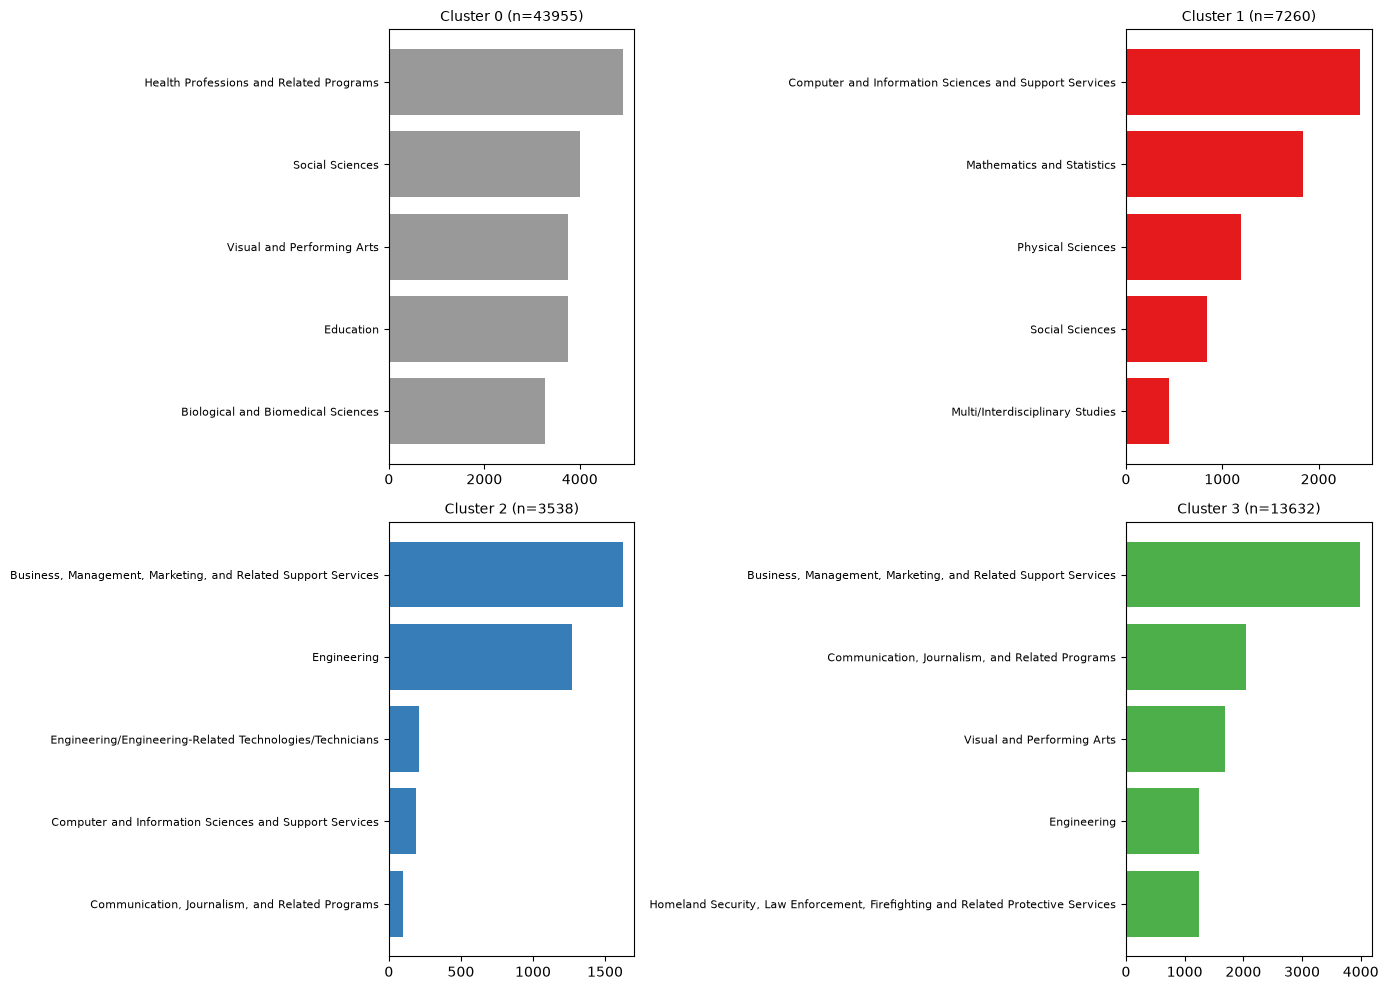

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, c in zip(axes.flat, sorted(d["cluster"].unique())):
    top5 = d[d["cluster"] == c]["cip_family_title"].value_counts().head(5)
    ax.barh(top5.index[::-1], top5.values[::-1], color=colors[c])
    ax.set_title(f"Cluster {c} (n={len(d[d['cluster']==c])})", fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig("cluster_top_fields.png", dpi=150)
plt.show()

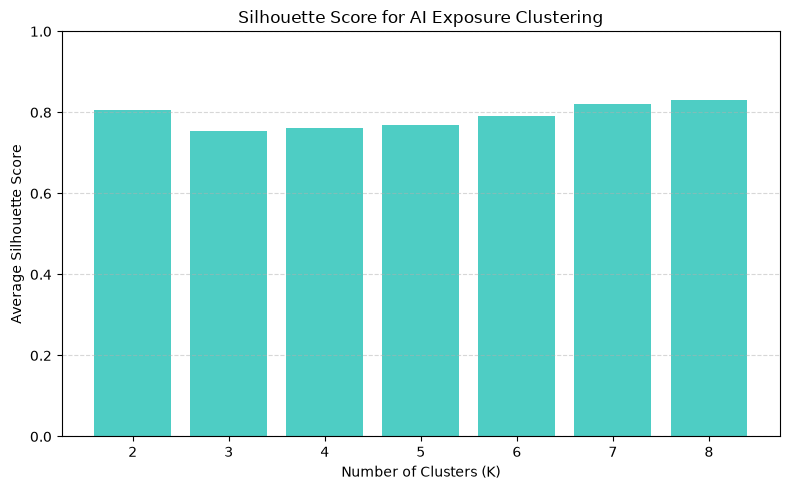

In [25]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(result_df["k"], result_df["silhouette"], color="#4ecdc4")
ax.set_xlabel("Number of Clusters (K)")
ax.set_ylabel("Average Silhouette Score")
ax.set_title("Silhouette Score for AI Exposure Clustering")
ax.set_ylim(0, 1.0)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("silhouette_bar.png", dpi=150)
plt.show()

---
## ขั้นตอนที่ 8 — ภาพประกอบผล (ฉบับภาษาไทย)
ตั้งฟอนต์ไทย (Windows: `Leelawadee UI`/`Tahoma`) ฟิต `scaler` และ K-Means ซ้ำด้วยพารามิเตอร์เดิม แล้ววาดภาพชุดเดียวกับขั้นตอนที่ 7 พร้อมชื่อกลุ่มภาษาไทย (`names_th`) บันทึกเป็นไฟล์ `*_th.png`

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# ฟอนต์ไทย
plt.rcParams["font.family"] = ["Leelawadee UI", "Tahoma"]
plt.rcParams["axes.unicode_minus"] = False   # กันเครื่องหมายลบเพี้ยน

# เก็บ scaler ไว้ใช้กับ centroid (ถ้ายังไม่เคยเก็บ ให้ fit ใหม่ตรงนี้)
scaler = StandardScaler()
Xs = scaler.fit_transform(d[["ai_software_occupation_share", "ai_tools_max_per_occupation"]])
kmeans_final = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Xs)
d["cluster"] = kmeans_final.labels_

colors = {0: "#999999", 1: "#e41a1c", 2: "#377eb8", 3: "#4daf4a"}
names_th = {
    0: "ไม่มีการเปิดรับ AI",
    1: "เข้มข้นสูง (กว้างปานกลาง)",
    2: "กว้างสูง เข้มข้นต่ำ",
    3: "กว้างต่ำ เข้มข้นต่ำ",
}

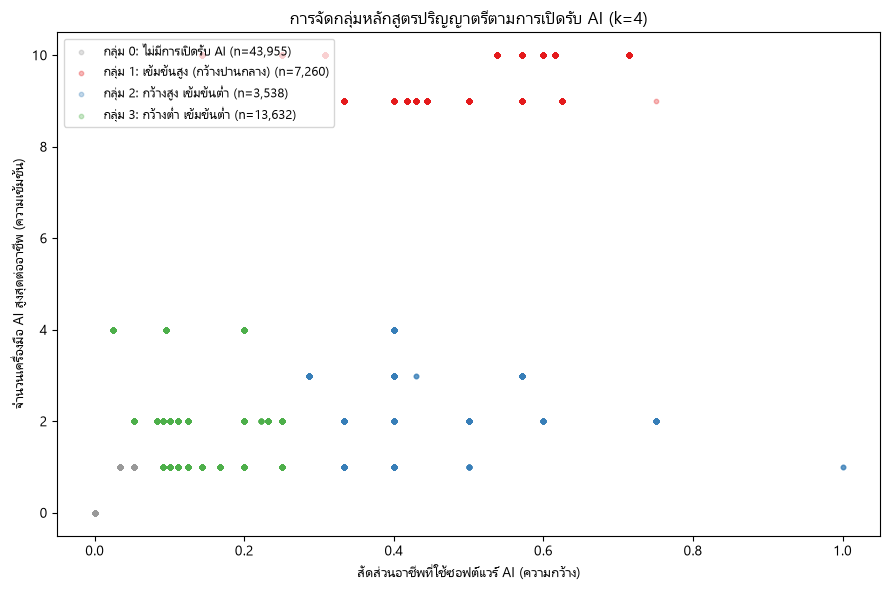

In [27]:
fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(d["cluster"].unique()):
    sub = d[d["cluster"] == c]
    ax.scatter(sub["ai_software_occupation_share"], sub["ai_tools_max_per_occupation"],
               s=10, alpha=0.3, color=colors[c],
               label=f"กลุ่ม {c}: {names_th[c]} (n={len(sub):,})")

ax.set_xlabel("สัดส่วนอาชีพที่ใช้ซอฟต์แวร์ AI (ความกว้าง)")
ax.set_ylabel("จำนวนเครื่องมือ AI สูงสุดต่ออาชีพ (ความเข้มข้น)")
ax.set_title("การจัดกลุ่มหลักสูตรปริญญาตรีตามการเปิดรับ AI (k=4)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("cluster_scatter_th.png", dpi=150)
plt.show()

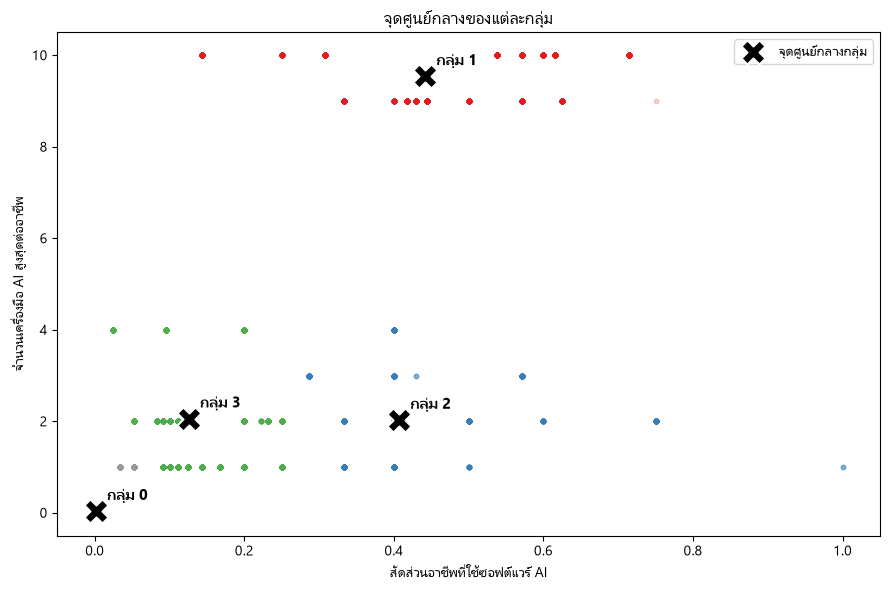

In [28]:
centroids = scaler.inverse_transform(kmeans_final.cluster_centers_)

fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(d["cluster"].unique()):
    sub = d[d["cluster"] == c]
    ax.scatter(sub["ai_software_occupation_share"], sub["ai_tools_max_per_occupation"],
               s=10, alpha=0.2, color=colors[c])

ax.scatter(centroids[:, 0], centroids[:, 1], c="black", marker="X", s=300,
           edgecolor="white", linewidth=1.5, label="จุดศูนย์กลางกลุ่ม", zorder=5)
for i, (x, y) in enumerate(centroids):
    ax.annotate(f"กลุ่ม {i}", (x, y), fontsize=11, fontweight="bold",
                xytext=(8, 8), textcoords="offset points")

ax.set_xlabel("สัดส่วนอาชีพที่ใช้ซอฟต์แวร์ AI")
ax.set_ylabel("จำนวนเครื่องมือ AI สูงสุดต่ออาชีพ")
ax.set_title("จุดศูนย์กลางของแต่ละกลุ่ม")
ax.legend()
plt.tight_layout()
plt.savefig("cluster_centroids_th.png", dpi=150)
plt.show()

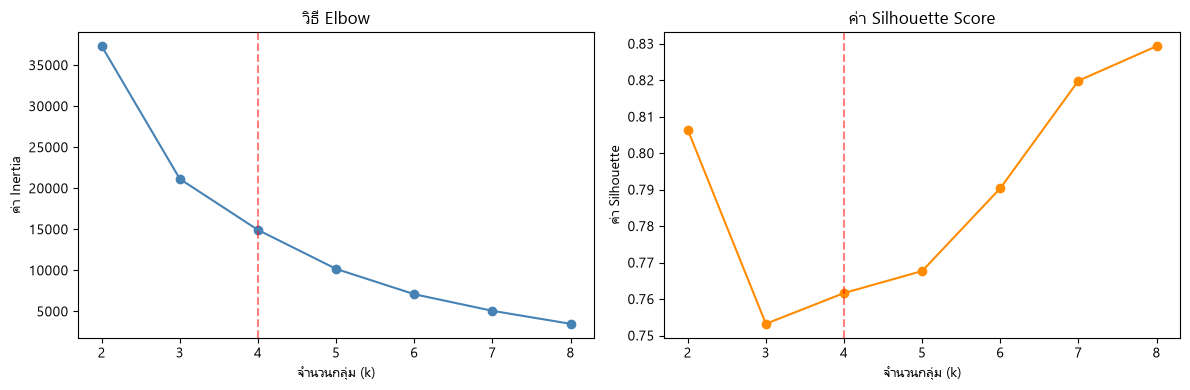

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(result_df["k"], result_df["inertia"], marker="o", color="steelblue")
axes[0].axvline(4, color="red", linestyle="--", alpha=0.5)
axes[0].set_xlabel("จำนวนกลุ่ม (k)")
axes[0].set_ylabel("ค่า Inertia")
axes[0].set_title("วิธี Elbow")

axes[1].plot(result_df["k"], result_df["silhouette"], marker="o", color="darkorange")
axes[1].axvline(4, color="red", linestyle="--", alpha=0.5)
axes[1].set_xlabel("จำนวนกลุ่ม (k)")
axes[1].set_ylabel("ค่า Silhouette")
axes[1].set_title("ค่า Silhouette Score")
plt.tight_layout()
plt.savefig("elbow_silhouette_th.png", dpi=150)
plt.show()

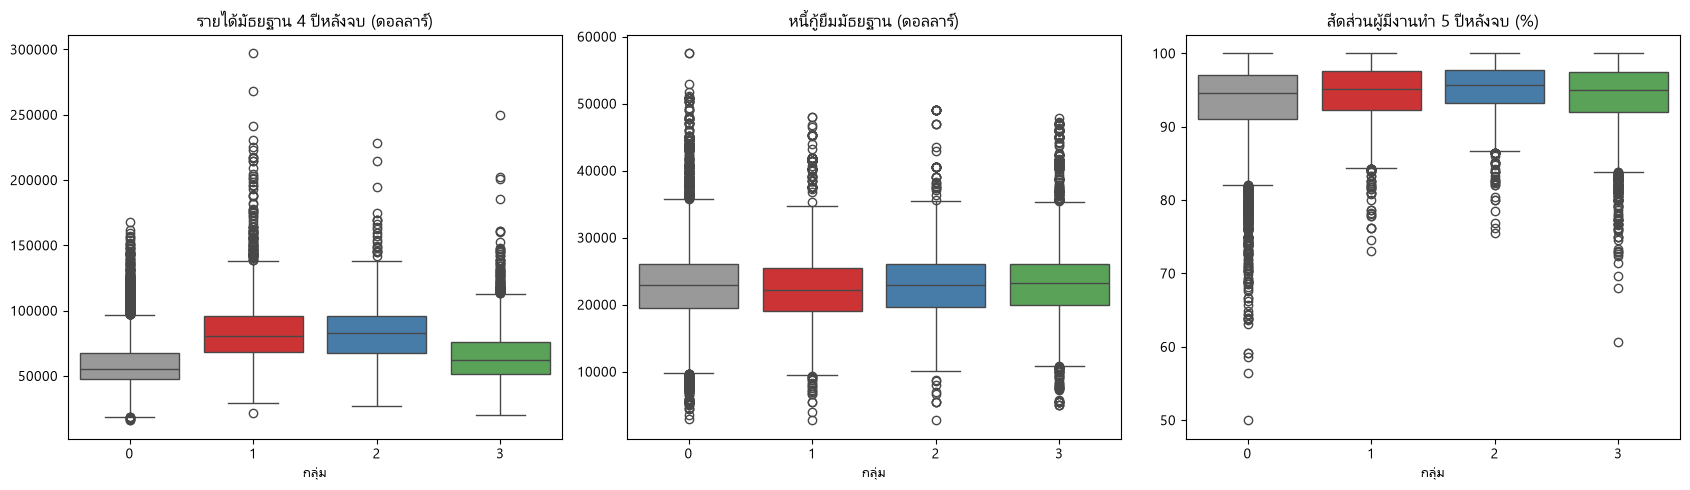

In [30]:
compare_vars = ["median_earnings_4yr_usd", "median_debt_usd", "pct_working_5yr"]
titles = ["รายได้มัธยฐาน 4 ปีหลังจบ (ดอลลาร์)", "หนี้กู้ยืมมัธยฐาน (ดอลลาร์)", "สัดส่วนผู้มีงานทำ 5 ปีหลังจบ (%)"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, var, title in zip(axes, compare_vars, titles):
    sns.boxplot(data=d, x="cluster", y=var, hue="cluster", palette=colors, legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("กลุ่ม")
    ax.set_ylabel("")
plt.tight_layout()
plt.savefig("cluster_boxplots_th.png", dpi=150)
plt.show()

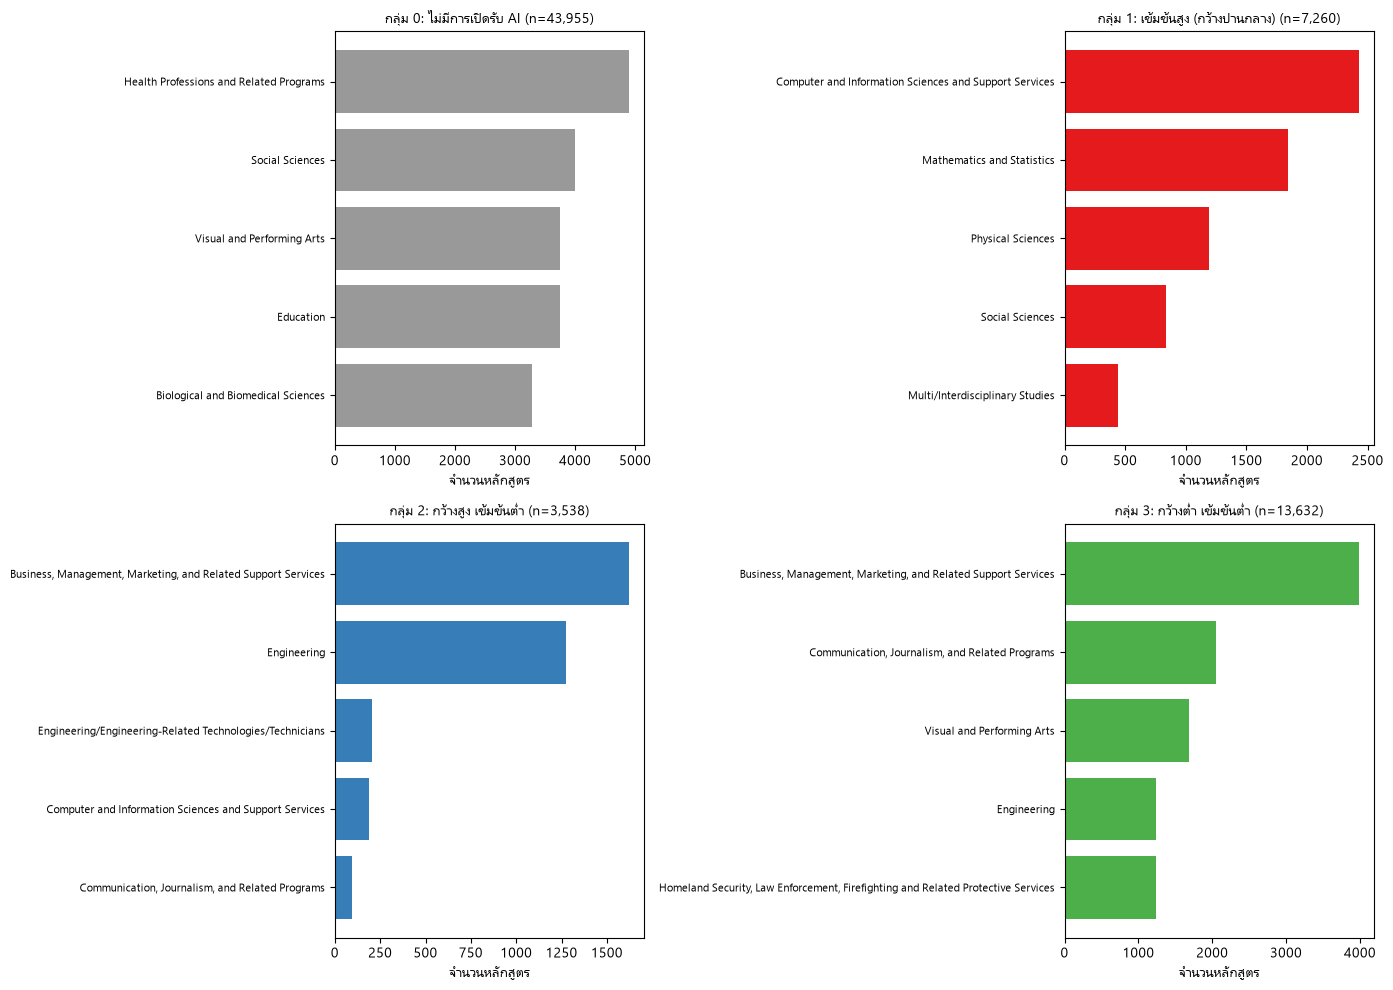

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, c in zip(axes.flat, sorted(d["cluster"].unique())):
    top5 = d[d["cluster"] == c]["cip_family_title"].value_counts().head(5)
    ax.barh(top5.index[::-1], top5.values[::-1], color=colors[c])
    ax.set_title(f"กลุ่ม {c}: {names_th[c]} (n={len(d[d['cluster']==c]):,})", fontsize=10)
    ax.set_xlabel("จำนวนหลักสูตร")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig("cluster_top_fields_th.png", dpi=150)
plt.show()

---
## สรุปผลการวิเคราะห์

**ผลลัพธ์หลัก** (ปริญญาตรี 68,385 หลักสูตร, K-Means k = 4)

| กลุ่ม | จำนวนหลักสูตร | รายได้มัธยฐาน 4 ปี (USD) | หนี้มัธยฐาน (USD) | % มีงานทำ 5 ปี (มัธยฐาน) |
|---|---|---|---|---|
| 0 ไม่มีการเปิดรับ AI | 43,955 | 55,532 | 23,000 | 94.60 |
| 1 เข้มข้นสูง | 7,260 | 80,623 | 22,125 | 95.10 |
| 2 กว้างสูง เข้มข้นต่ำ | 3,538 | 82,632 | 23,000 | 95.75 |
| 3 กว้างต่ำ เข้มข้นต่ำ | 13,632 | 61,884 | 23,250 | 95.00 |

**การทดสอบทางสถิติ (Kruskal–Wallis)**

| ตัวแปร | H | p-value | n | ε² |
|---|---|---|---|---|
| รายได้มัธยฐาน 4 ปี | 4,032.12 | ≈ 0 | 26,605 | 0.152 |
| หนี้มัธยฐาน | 76.04 | 2.2 × 10⁻¹⁶ | 25,070 | 0.003 |
| % มีงานทำ 5 ปี | 166.81 | 6.2 × 10⁻³⁶ | 23,891 | 0.007 |

**ข้อสรุป**

- หลักสูตรกว่า 6 ใน 10 (61.8%) ไม่มีการเปิดรับ AI เลย และการจัดกลุ่มแยก 4 กลุ่มได้ชัดเจน (Silhouette 0.762)
- **รายได้ต่างกันชัดเจนและมีขนาดผลปานกลาง** (ε² ≈ 0.15): กลุ่ม 1 และ 2 มีรายได้มัธยฐานสูงกว่ากลุ่ม 0 ราว 25,000–27,000 ดอลลาร์ ส่วนกลุ่ม 3 สูงกว่ากลุ่ม 0 ราว 6,000 ดอลลาร์
- **หนี้และการมีงานทำต่างกันอย่างมีนัยสำคัญทางสถิติ แต่ขนาดผลเล็กมาก** (ε² < 0.01) ค่ามัธยฐานของแต่ละกลุ่มใกล้กัน (หนี้ 22,125–23,250 ดอลลาร์, มีงานทำ 94.6–95.75%) จึงไม่ควรตีความว่าต่างกันในทางปฏิบัติ

**ข้อจำกัดในการตีความ**

- เป็นความสัมพันธ์ ไม่ใช่เหตุและผล: กลุ่มที่เปิดรับ AI สูงมักเป็นสาขาที่รายได้สูงอยู่แล้ว และตัวแปร `ai_*` วัดการเปิดรับ AI ของอาชีพที่เกี่ยวข้อง ไม่ได้วัดการสูญเสียงานหรือผลกระทบจริง
- ข้อมูลรายได้/หนี้/การมีงานทำไม่ครบทุกหลักสูตร: การทดสอบใช้เพียง ~24,000–27,000 จาก 68,385 หลักสูตร (ประมาณ 35–39%) ซึ่งอาจไม่เป็นตัวแทนของทั้งหมด (โดยทั่วไปข้อมูลระดับหลักสูตรจะถูกปกปิดเมื่อกลุ่มตัวอย่างเล็ก)
- หน่วยวิเคราะห์คือ "หลักสูตร" โดยแต่ละหลักสูตรมีน้ำหนักเท่ากัน ไม่ได้ถ่วงน้ำหนักด้วยจำนวนผู้สำเร็จการศึกษา
- ตัวแปรจัดกลุ่มเบ้และมีค่า 0 จำนวนมาก K-Means จึงแยกกลุ่ม "ศูนย์" ออกเป็นกลุ่มใหญ่ที่สุด ผลการจัดกลุ่มจึงไวต่อการเลือก k และการปรับสเกล